In [1]:

def update3(Wup,Bup, W, B,eta, beta,rho,rhof,e, AiW,FiW,AiB,FiB, ViW,ViB,i,t,optimizer):
  eta=np.array(eta)
  
  rho=np.array(rho)
  rhof=np.array(rhof)
  #AiW=Ai[0]; AiF=Ai[1]; FiW=Fi[0]; FiB=Fi[1]
  t+=1
  # if t%55==0:
  #   t=1; Aiw=0; AiB=0; FiW=0;FiB=0
  # if i%BATCH==0:
  #    t=1

  WC=copy.deepcopy(W); BC=copy.deepcopy(B)
  try:
    if optimizer=='momentum':
      # ViW=beta*ViW+eta*np.array(Wup)
      # ViB=beta*ViB+eta*np.array(Bup)
      # W+=ViW
      # B+=ViB
      ViW=(beta*ViW+(1-beta)*np.array(Wup))/(1-beta**t)
      
      ViB=(beta*ViB+(1-beta)*np.array(Bup))/(1-beta**t)

  
      # W=[W[i]-eta*ViW[i] for i in range(len(W))]
      # B=[B[i]-eta*ViB[i] for i in range(len(B))]
      W-=eta*ViW
      B-=eta*ViB


    
    
    if optimizer=='adam':
      #ADAM UPDATE OPTIMIZER######################
      #AiW=rho*AiW+(1-rho)*np.array([np.power(Wup[i],2) for i in range(len(W))])
      #FiW=rhof*FiW+(1-rhof)*np.array([Wup[i] for i in range(len(W))])
      AiW=rho*AiW+(1-rho)*np.power(Wup,2)
      FIW=rhof*FiW+(1-rhof)*np.array(Wup)

      AiB=rho*AiB+(1-rho)*np.power(Bup,2)
      FiB=rhof*FiB+(1-rhof)*np.array(Bup)
      
      AiW_=AiW/(1-rho**t); FiW_=FiW/(1-rhof**t)
      AiB_=AiB/(1-rho**t); FiB_=FiB/(1-rhof**t)
      
      # W=[W[i]-eta/np.sqrt(AiW+e)*FiW[i] for i in range(len(FiW))]
      # B=[B[i]-eta/np.sqrt(AiB+e)*FiB[i] for i in range(len(FiB))]
      
      #W-=(eta/((AiW+e)**0.5))*FiW
      #B-=(eta/((AiB+e)**0.5))*FiB

      W-=(eta/((AiW_)**0.5)+e)*FiW_
      B-=(eta/((AiB_)**0.5)+e)*FiB_
    #############################
    if optimizer=='RMSProp':
        
      #RMSProp OPTIMIZER######################
      #AiW=rho*AiW+(1-rho)*np.array([np.power(Wup[i],2) for i in range(len(W))])
      #FiW=rhof*FiW+(1-rhof)*np.array([Wup[i] for i in range(len(W))])
      AiW=rho*np.power(AiW,2)+(1-rho)*np.power(Wup,2)
      #FIW=rhof*FiW+(1-rhof)*np.array(Wup)

      AiB=rho*np.power(AiB,2)+(1-rho)*np.power(Bup,2)
      #FiB=rhof*FiB+(1-rhof)*np.array(Bup)
      
      AiW_=AiW/(1-rho**t)
      AiB_=AiB/(1-rho**t)
      
      # W=[W[i]-eta/np.sqrt(AiW+e)*FiW[i] for i in range(len(FiW))]
      # B=[B[i]-eta/np.sqrt(AiB+e)*FiB[i] for i in range(len(FiB))]
      
      # W-=eta/((AiW)**0.5+e)*np.array(Wup)
      # B-=eta/((AiB)**0.5+e)*np.array(Bup)


      W-=eta/((AiW_)**0.5+e)*np.array(Wup)
      B-=eta/((AiB_)**0.5+e)*np.array(Bup)
      #############################
    # W=[W[i]-eta*Wup[i] for i in range(len(W))]
    #B=[B[i]-eta*Bup[i] for i in range(len(B))]
    #W=W-Wup #eta*np.array([dE_dO2*dO2_dO1,dE_dO2*dO2_dO1]).T*dO1_dW1
    
    #B=B-Bup #eta*dE_dO2*dO2_dO1*dO1_dB
  except Exception as E:
    print(E)
    
    W=WC; B=BC
    


  # W=[np.array(W[i]) for i in range(len(W))]
  # B=[np.array(B[i]) for i in range(len(B))]
  return (W,B, AiW, AiB,FiW,FiB,t)

In [2]:

def update2(Wup,Bup, W, B,eta):
  eta=np.array(eta)
  WC=copy.deepcopy(W); BC=copy.deepcopy(B)
  try:
    W-=eta*Wup
    B-=eta*Bup
    # W=[W[i]-eta*Wup[i] for i in range(len(W))]
    # B=[B[i]-eta*Bup[i] for i in range(len(B))]
    #W=W-Wup #eta*np.array([dE_dO2*dO2_dO1,dE_dO2*dO2_dO1]).T*dO1_dW1
    
    #B=B-Bup #eta*dE_dO2*dO2_dO1*dO1_dB
  except:
    W=WC; B=BC


  # W=[np.array(W[i]) for i in range(len(W))]
  # B=[np.array(B[i]) for i in range(len(B))]
  return (W,B)

In [3]:
def dA_dI(I):
  da_di=np.exp(-np.array(I))/(1+np.exp(-np.array(I)))**2
  return da_di

  

In [4]:
def backward2(W,A,I,X, y, k=1):
#  k=1
  
  #dE_dIn=-1*((y*(1/I[-1])+(1-y)*(1/(1-I[-1])))) 
  #dE_dAn=-1*((y*(np.log(I[-1]))+(1-y)*((1-np.log(I[-1]))))) 
  #si=sigmoid

  #---
  #print("I[-]=",I[-1])
  An=A[-1]
  dE_dAn  =-1*((y*(np.log(1/An))+(1-y)*((1-np.log(1/(1-An)))))) 
  #dE_dAn  =-1*((y*(np.log(An))+(1-y)*((np.log((1-An)))))) 
  #dE_dAn  =-1*((y*((An))+(1-y)*((1-((An)))))) 
  #dE_dAn  =-1*((y*(np.log(1/An))+(y-1)*((np.log(1/(1-An)))))) 
  #dE_dAn  =-1*((y*(np.abs(np.log(An)))+(y-1)*(np.abs(np.log((1-An)))))) 


  #dE_dAn=-1*(y*((1/An))+(y-1)*(1/(1-An)))
  
  dAn_dIn=sigmoid(I[-1])*(1-sigmoid(I[-1]))

  #---


  #print(dE_dIn)
  n=len(N)-1
  #derives=[]
  derives=dE_dAn*dAn_dIn
  for i in range(k): #k<n
    #print(i)
    #derives.append(W[n-i]) #dI_(n)/dA_(n-1)
    #try:
    if i==0:
      derives*=W[n-i] #dI_(n)/dA_(n-1)
    #except:
    else:
      # print("derives: ",derives)
      # print(" W[n-i].T: ", W[n-i].T)
      #changed oct 14 20#########-------------
      # derives=np.array([derives*x for x in W[n-i].T]).T
      # derives=np.sum(derives, axis=0)
      ############################-------------
      derives=np.dot(derives,W[n-i])
    #derives.append(dA_dI(I[n-i-1]) ) #dA_(n-1)/dI_(n-1)
    #print(I[n-i-1])
    
    #---sigmoid
    #derives*=dA_dI(I[n-i-1])  #dA_(n-1)/dI_(n-1)
    #----
    #----relu sep 9 20
    # print("nnnnnnnn:",n)
    # print("iiiiiiiiii:",i)
    #print("da_di########################:",np.array([0 if e==0 else 1 for e in A[n-i-1] ]))
    #derives*=np.array([0 if e==0 else 1 for e in A[n-i-1] ])

    #leaky
    derives*=np.array([0.01 if e<0 else 1 for e in A[n-i-1] ])
    #-----

  #derives.append(A[n-k-1]) #dI_(k)/dW_(k)
  if k<n:
    
    derivesW=np.array([derives*x for x in A[n-k-1] ]).T#dI_(k)/dW_(k)

    #derivesW=derives*A[n-k-1] #dI_(k)/dW_(k)
    #print("derivesW:",derivesW)
  if k==n:
    derivesW=np.array([derives*x for x in X[0]]).T#dI_(k)/dW_(k)
  
  # derivesW=[np.array(derivesW[i]) for i in range(len(derivesW))]
  # derives=[np.array(derives[i]) for i in range(len(derives))]
  #return (eta*dE_dIn*derivesW, eta*dE_dIn*derives, dE_dIn)
  #return (eta*dE_dAn*dAn_dIn*derivesW, eta*dE_dAn*dAn_dIn*derives, dE_dAn)
  return (derivesW, derives, dE_dAn)

#   #print(derivesW, derives)
#   #W[4]
#   W[n-k]
#   #W[0]
# backward2(W,A,I,X)

In [5]:
def generateWandB(N):
  #lx=len(X) # = 2


  W=[]; B=[]

  for i in range(1,len(N)):
    #W.append(np.array(np.random.normal(0, 1, N[i]*N[i-1]) ).reshape(N[i],N[i-1]))
    
    #---He et al weight initialization
    W.append(np.array(np.random.normal(0, 1, N[i]*N[i-1])*np.sqrt(2/N[i-1]) ).reshape(N[i],N[i-1]))
    #----

    B.append(np.random.normal(0, 1, N[i]))
  W.append(np.random.normal(0, 1, N[-1]))
  
  W=[np.array(W[i]) for i in range(len(W))]
  B=[np.array(B[i])*0 for i in range(len(B))]
  return (W,B)

In [6]:
def forward2(W, B, X):
  I=[]
  A=[]
  #I.append(X[0])
  I.append(np.dot(W[0],X[0])+B[0])  #12x2*2*1+12 => 12x1

  for i in range(1, len(N)):
    #print(i)
    #---sigmoid
    #A.append(sigmoid(I[i-1])) #12x1
    #----

    #---relu sep 9 20
    A.append(relu(I[i-1]))
    #print("A:",A)
    #----

    #print(A[i-1])
    if i<len(N)-1:
      #print('N: ',N)
      I.append(np.dot(W[i],A[i-1])+B[i]) #12x1*2x12
    else:
      I.append(np.dot(W[i],A[i-1]))
  A.append(sigmoid(I[-1]))
  #---relu sep 9 20
  #A.append(relu(I[-1]))
  
  #-----

  #I.append(np.dot(W[-1],A[-1]))
  #print("A={}, I={}".format(A,I))
  return(A,I)

In [7]:
def sumMat(xup):
  array=[]
  l=([(xup[i][j]) for j in range(len(xup[0])) for i in range(len(xup))])
  for k in range(len(l))[::len(xup)]:
    array.append((np.sum(l[k:k+len(xup)],axis=0)))
#    print("---------")
  return array

In [8]:
def sumMat2(xup):
    xup=np.sum(np.array(xup),axis=0)
    return xup

In [9]:
#df.iloc[:,:2]
#for row in df.iloc[np.where(df[2]==0)].iloc[:,:2]:
#df2=df.iloc[np.where(df[2]==0)].iloc[:,:2]
#test=df[:thresh]

#agg=[]
# for row in test0.iterrows():
#   x1=row[1][0]; x2=row[1][1]
#   print(forward2(W, B, [[x1,x2]])[0][-1])


def testAcuracy(test, W, B):

  test0=test.iloc[np.where(test[2]==0)]
  test1=test.iloc[np.where(test[2]==1)]


  pred0=[forward2(W, B, [[row[1][0],row[1][1]]])[0][-1] for row in test0.iterrows()]
  pred1=[forward2(W, B, [[row[1][0],row[1][1]]])[0][-1] for row in test1.iterrows()]

  mp0=np.mean(pred0)+2*np.std(pred0)
  mp1=np.mean(pred1)-0.5*np.std(pred1)
  
  if len(pred1)>0 and  len(pred0) >0:
    acc=((sum(pred0<=mp0)/len(pred0))+(sum(pred1>=mp1)/len(pred1)))/2

    mp=np.array(0.85)

    acc=((sum(pred0<=mp0)/len(pred0))+(sum(pred1>=mp0)/len(pred1)))/2
    return acc



  return 0
  
  
  #print(forward2(W, B, [[x1,x2]])[0][-1])

#forward2(W, B, [[8,8]])[0][-1]

In [10]:
#!pip install seaborn

c:\users\roy\anaconda3\envs\tensorflow_2.x.2\lib\site-packages\seaborn\_decorators.py:43: FutureWarning: Pass the following variables as keyword args: x, y. From version 0.12, the only valid positional argument will be `data`, and passing other arguments without an explicit keyword will result in an error or misinterpretation.
  FutureWarning
c:\users\roy\anaconda3\envs\tensorflow_2.x.2\lib\site-packages\seaborn\_decorators.py:43: FutureWarning: Pass the following variables as keyword args: x, y. From version 0.12, the only valid positional argument will be `data`, and passing other arguments without an explicit keyword will result in an error or misinterpretation.
  FutureWarning


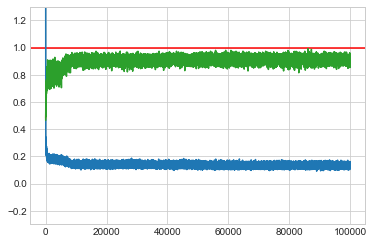

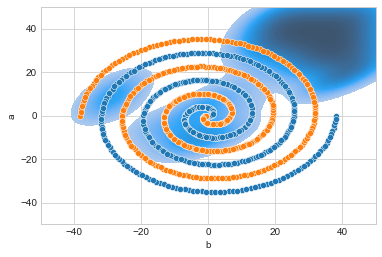

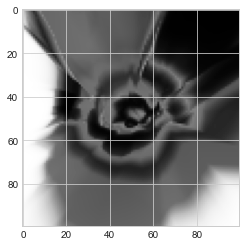

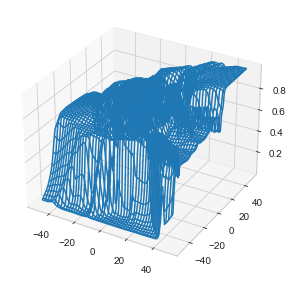

max:  0.9983737955529537 min:  1.4909208065629934e-05
abs(max-min):  0.998358886344888
Loss = 0.148; epoch = 99999; train acc. = 0.914; test acc. = 0.915.

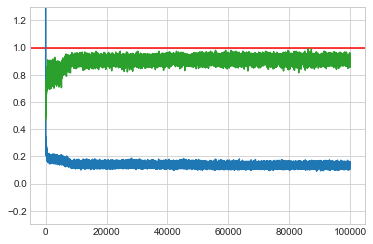

In [13]:
import numpy as np
import matplotlib.pyplot as plt

import math
r=65
a,b=-12,10
n=100
a=12
p=.051
rng=np.linspace(-6,6,n)
rngy=np.linspace(a,-a,n)
rngx=np.linspace(-a,a,n)
psq=[]; psq2=[]
xy_1=[]

#####################################################
#SQUARE
a2=11.0
rr=1.0
for x in rngx:
    for y in rngy:


        # if np.random.choice([1,-1],p=[p,1-p])>0:
        #   if (x<-rr and x>-(a2) and y<(a2) and y>rr):# \
            
        #   #or ( x>rr and x<(a) and y<-rr and y>-(a)):
        #     #p.append((x+r1,y+r2))
        #     psq.append((x,y))
        #   if (x<(a2) and x>rr and y>rr and y<(a2) ) or ( x<-rr and x>-(a2) and y<-rr and y>-(a2)) or ( x>rr and x<(a2) and y<-rr and y>-(a2)):
        #     psq2.append((x,y))

            
        if np.random.choice([1,-1],p=[p,1-p])>0:
          if (x<-rr and x>-(a2) and y<(a2) and y>rr) \
          or ( x>rr and x<(a2) and y<-rr and y>-(a2)):
            #p.append((x+r1,y+r2))
            psq.append((x,y))
          if (x<(a2) and x>rr and y>rr and y<(a2) ) or ( x<-rr and x>-(a2) and y<-rr and y>-(a2)) :# or ( x>rr and x<(a) and y<-rr and y>-(a)):
            psq2.append((x,y))





from IPython.display import clear_output
%matplotlib inline
import matplotlib.pyplot as plt
plt.style.use('seaborn-whitegrid')


xs=[i[0] for i in psq]
ys=[i[1] for i in psq]


xs_2=[i[0] for i in psq2]
ys_2=[i[1] for i in psq2]



a=10; R=10

#######################################
##Spiral1
# theta1 = np.radians(np.linspace(0,360*5.1,1000))
# theta2 = np.radians(np.linspace(0,360*5,1000))
# r1 = 10*theta1**2
# r2 =10* theta2**2



# xs_2 = (r1*np.cos(theta1))[:700]+np.random.ranf(len((r1*np.cos(theta1))[:700]))*100

# ys_2 = (r1*np.sin(theta1))[:700]+np.random.ranf(len((r1*np.cos(theta1))[:700]))*100

# xs = (r2*np.cos(theta2))[700:]+np.random.ranf(len((r2*np.cos(theta2))[700:]))*100
# ys = (r2*np.sin(theta2))[700:]+np.random.ranf(len((r2*np.cos(theta2))[700:]))*100

# xs=[normalize(xs[i],xs)*20-10 for i in range(len(xs))]
# ys=[normalize(ys[i],ys)*20-10 for i in range(len(ys))]

# xs_2=[normalize(xs_2[i],xs_2)*10-6.5 for i in range(len(xs_2))]
# ys_2=[normalize(ys_2[i],ys_2)*10-3 for i in range(len(ys_2))]


#Waves 2
# nr=np.random.uniform(-10,10,500)
# xs=nr+3
# ys=np.sin(nr)

# nr2=np.random.uniform(-10,10,500)
# xs_2=nr
# ys_2=np.sin(nr)+2




# nr=np.random.uniform(-10,10,500)
# xs=nr-1+np.random.ranf(len(nr))
# ys=np.sin(nr)+np.random.ranf(len(nr))

# nr2=np.random.uniform(-10,10,500)
# xs_2=nr-np.random.ranf(len(nr))
# ys_2=np.sin(nr)+2+np.random.ranf(len(nr))


#####################################
####################################
#waves1
# nr=np.random.uniform(-10,10,500)
# xs=nr-1+np.random.ranf(len(nr))
# ys=np.sin(nr)+np.random.ranf(len(nr))

# nr2=np.random.uniform(-10,10,500)
# xs_2=nr-np.random.ranf(len(nr))
# ys_2=np.sin(nr)+4+np.random.ranf(len(nr))

# nr3=np.random.uniform(-10,10,500)
# xs_3=nr3-1+np.random.ranf(len(nr3))
# ys_3=np.sin(nr3)-4+np.random.ranf(len(nr3))


################################
##################


# # #Circle

# r=65
# a,b=-12,10
# n=500
# rng=np.linspace(-6,6,n)
# rngy=np.linspace(a,-a,n)
# rngx=np.linspace(-a,a,n)
# p=[]
# xy_1=[]
# for x in rngx:
#     for y in rngy:
#         #xy.append(((x,y)))
#         #z= rng[x]**2+rng[y]**2
#         # z=-1/(1+ math.exp((-1)*((1/(1+math.exp((-1)*(x*w1+y*w2+b1))))*(w3)))) -\
#         # 1/(1+ math.exp((-1)*((1/(1+math.exp((-1)*(x*w4+y*w5+b2))))*(w6))))-\
#         # 1/(1+ math.exp((-1)*((1/(1+math.exp((-1)*(x*w7+y*w8+b3))))*(w9))))
#         z=x**2+y**2-r
#         xy_1.append(z)
#         r1=np.random.randint(-7,7)*0.17
#         r2=np.random.randint(-7,7)*0.17
#         if z<0.1 and z>-0.1:
#           p.append((x+r1,y+r2))


# r=4.25
# a,b=-6,6
# a=-12
# n=500
# rng=np.linspace(-6,6,n)
# rngy=np.linspace(a,-a,n)
# rngx=np.linspace(-a,a,n)
# p_2=[]
# xy_2=[]
# for x in rngx:
#     for y in rngy:
#         #xy.append(((x,y)))
#         #z= rng[x]**2+rng[y]**2
#         # z=-1/(1+ math.exp((-1)*((1/(1+math.exp((-1)*(x*w1+y*w2+b1))))*(w3)))) -\
#         # 1/(1+ math.exp((-1)*((1/(1+math.exp((-1)*(x*w4+y*w5+b2))))*(w6))))-\
#         # 1/(1+ math.exp((-1)*((1/(1+math.exp((-1)*(x*w7+y*w8+b3))))*(w9))))
#         z=x**2+y**2-r
#         xy_2.append(z)
#         r1=np.random.randint(-5,5)*0.43
#         r2=np.random.randint(-5,5)*0.43
#         if z<0.1 and z>-0.1:
#           p_2.append((x+r1,y+r2))
#           #p_2.append((x,y))         
# xs=[i[0] for i in p]
# ys=[i[1] for i in p]


# xs_2=[i[0] for i in p_2]
# ys_2=[i[1] for i in p_2]

#####################



#####################################################
# #Circle2

# r=65
# a,b=-12,10

# r=14.25
# a,b=-6,6
# a=-12

# n=500
# rng=np.linspace(-6,6,n)
# rngy=np.linspace(a,-a,n)
# rngx=np.linspace(-a,a,n)
# p=[]
# xy_1=[]
# for x in rngx:
#     for y in rngy:
#         #xy.append(((x,y)))
#         #z= rng[x]**2+rng[y]**2
#         # z=-1/(1+ math.exp((-1)*((1/(1+math.exp((-1)*(x*w1+y*w2+b1))))*(w3)))) -\
#         # 1/(1+ math.exp((-1)*((1/(1+math.exp((-1)*(x*w4+y*w5+b2))))*(w6))))-\
#         # 1/(1+ math.exp((-1)*((1/(1+math.exp((-1)*(x*w7+y*w8+b3))))*(w9))))
#         z=(x+10)**2+(y-0)**2-r
#         xy_1.append(z)
#         r1=np.random.randint(-7,7)*0.17
#         r2=np.random.randint(-7,7)*0.17
#         if z<0.1 and z>-0.1:
#           p.append((x+r1,y+r2))







# r=14.25
# a,b=-6,6
# a=-12
# n=500
# rng=np.linspace(-6,6,n)
# rngy=np.linspace(a,-a,n)
# rngx=np.linspace(-a,a,n)
# p_2=[]
# xy_2=[]
# for x in rngx:
#     for y in rngy:
#         #xy.append(((x,y)))
#         #z= rng[x]**2+rng[y]**2
#         # z=-1/(1+ math.exp((-1)*((1/(1+math.exp((-1)*(x*w1+y*w2+b1))))*(w3)))) -\
#         # 1/(1+ math.exp((-1)*((1/(1+math.exp((-1)*(x*w4+y*w5+b2))))*(w6))))-\
#         # 1/(1+ math.exp((-1)*((1/(1+math.exp((-1)*(x*w7+y*w8+b3))))*(w9))))
#         z=x**2+y**2-r
#         xy_2.append(z)
#         r1=np.random.randint(-5,5)*0.17#43
#         r2=np.random.randint(-5,5)*0.17#43
#         if z<0.1 and z>-0.1:
#           p_2.append((x+r1,y+r2))
#           #p_2.append((x,y))         
# xs=[i[0] for i in p]
# ys=[i[1] for i in p]


# xs_2=[i[0] for i in p_2]
# ys_2=[i[1] for i in p_2]
#####################################################


########################################
#Circle3
# nr=np.random.normal(0,10,500)#. uniform(-10,10,500)
# xs=np.sin(nr)*10+np.random.ranf(len(nr))
# ys=np.cos(nr)*10+np.random.ranf(len(nr))

# nr2=np.random.uniform(-10,10,500)
# xs_2=np.sin(nr)*5-np.random.ranf(len(nr))
# ys_2=np.cos(nr)*5+4+np.random.ranf(len(nr))

# nr3=np.random.uniform(-10,10,500)
# xs_3=np.sin(nr3)*17+np.random.ranf(len(nr3))
# ys_3=np.cos(nr3)*17+np.random.ranf(len(nr3))

# nr4=np.random.uniform(-10,10,500)
# xs_4=np.sin(nr4)*11.7+np.random.ranf(len(nr4))*1.1
# ys_4=np.cos(nr4)*11.7+np.random.ranf(len(nr4))*1.1


# ss=[(xs[i],ys[i],1) for i in range(len(xs))]
# ss_2=[(xs_2[i],ys_2[i],0) for i in range(len(xs_2))]
# ss_3=[(xs_3[i],ys_3[i],1) for i in range(len(xs_3))]
# ss_4=[(xs_4[i],ys_4[i],0) for i in range(len(xs_4))]

##################################################


# #circle 4
# nr=np.random.normal(0,10,500)#. uniform(-10,10,500)
# xs=np.sin(nr)*10+np.random.ranf(len(nr))
# ys=np.cos(nr)*10+np.random.ranf(len(nr))

# nr2=np.random.uniform(-10,10,500)
# xs_2=np.sin(nr)*5+np.random.ranf(len(nr))
# ys_2=np.cos(nr)*5+4+np.random.ranf(len(nr))

# nr3=np.random.uniform(-10,10,500)
# xs_3=np.sin(nr3)*13+np.random.ranf(len(nr3))
# ys_3=np.cos(nr3)*13+np.random.ranf(len(nr3))

# nr4=np.random.uniform(-10,10,500)
# xs_4=np.sin(nr4)*17.0+np.random.ranf(len(nr4))
# ys_4=np.cos(nr4)*17.0+np.random.ranf(len(nr4))


# ss=[(xs[i],ys[i],1) for i in range(len(xs))]
# ss_2=[(xs_2[i],ys_2[i],0) for i in range(len(xs_2))]
# ss_3=[(xs_3[i],ys_3[i],1) for i in range(len(xs_3))]
# ss_4=[(xs_4[i],ys_4[i],0) for i in range(len(xs_4))]
# a=20; R=20
######################################################

# ##Spiral----------------##################################


a = 0.5
b = 2

a1 = -a
b1 = -b
p=6
t = np.linspace(0,p*math.pi, 500)
t = np.linspace(0,p*math.pi, 500)

rad=50

# # x = (a + b*t) * np.cos(t)
# # y = (a + b*t) * np.sin(t)

# axes = plt.gca()
# axes.set_xlim([-rad,rad])
# axes.set_ylim([-rad,rad])

x = (a + b*t) * np.cos(t)
y = (a + b*t) * np.sin(t)

x1 = (a1 + b1*t) * np.cos(t)
y1 = (a1 + b1*t) * np.sin(t)

xs=x;ys=y;xs_2=x1;ys_2=y1

a=rad; R=rad
#############################################################_---------------------------

#############LATTICE##################--------------------------------------------------

# import numpy as np
# import math
# import matplotlib.pyplot as plt
# axes = plt.gca()
# rad=30
# axes.set_xlim([-rad,rad])
# axes.set_ylim([-rad,rad])

# nr=np.random.normal(0,3,5000)#. uniform(-10,10,500)
# xs=nr+np.sin(nr*1.5)/np.cos(nr*1.2)*4.51+np.random.ranf(len(nr))
# ys=nr*np.cos(nr*.2)*7+np.cos(nr*2)*1+np.random.ranf(len(nr))


# xs_2=ys
# ys_2=xs


# a=rad; R=rad

#############LATTICE##################--------------------------------------------------


# plt.scatter(x,y)
# plt.show()
axes = plt.gca()
axes.set_xlim([a,-a])
axes.set_ylim([a,-a])
#plt.contourCircle()  (x,y,'o', color='black')
# p
# xs
#ys
#plt.plot(-1.5,1.6,'ro') 
# plt.scatter(xs,ys,color='k') 
# #plt.scatter(xs_2,ys_2, color='g') 
# plt.scatter(xs_2,ys_2, color='g')


#p

#plt.imshow(xy4.T)
#plt.show()
#clear_output()
#xs_2


#a=-12
# N=50
# rngy=np.linspace(a,-a,N)
# rngx=np.linspace(-a,a,N)



# ss=[(xs[i],ys[i],1) for i in range(len(xs))]
# ss_2=[(xs_2[i],ys_2[i],0) for i in range(len(xs_2))]




# s=[[int(s[0]),int(s[1])] for s in ss]
# s2=[[int(s[0]),int(s[1])] for s in ss_2]
# l=[]
# for x in rngx:
#   for y in rngy:
#     if [int(x),int(y)] not in s+s2:
#       l.append((x,y,0))


# import pandas as pd 

# df_z=pd.DataFrame(l)
# df_z=df_z.sample(frac=1).reset_index(drop=True)



# plt.scatter(df_z[1],df_z[0], color='b',alpha=0.1)


import seaborn as sns
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline


b1=3.7;b2=-3.5;b3=-3.9
w1=0.28;w2=1.9;w3=5.5
w4=-1.2;w5=1.2;w6=-5.7
w7=1.7;w8=0.55;w9=-5.6

def plot2(W,B,W1,W2,Bx,train, a, R, r=0.98, concave=False):

  
  #W1=W1.reshape(-1,1)
  import math
  xx=[];yy=[];zz=[]
  n_=100
  #a=10#12
  rng=np.linspace(-6,6,n_)
  rngx=np.linspace(-a,a,n_)
  rngy=np.linspace(a,-a,n_)
  p3=[]; p4=[]; p5=[]
  xy_x=[]
  xy_x2=[]
  for x in rngx:
      for y in rngy:

          o=[]
          X=[[x,y]]
          z=forward2(W,B,X)[0][-1]
          # for i in range(0,n*2,2):
          #   #print(i,i+1,int(i/2))
          
          #   o.append(sigmoid(W1[i]*x+W1[i+1]*y+Bx[int(i/2)])*W2[int(i/2)])

         # z=sum(o)
          
          xy_x.append(z)





  xy4=np.array(xy_x).reshape(n_,n_)



#TAKE QUANTILES (r)
  if concave:
    r=1-r
  pp=[]
  A=np.sort(xy4.reshape(1,-1))[0]
  for i in range(n_):
    for j in range(n_):

      if concave:
        if xy4[i,j]<=max(set(list(A[:int(len(A)*r)]))):
          pp.append((rngx[i],rngy[j]))
      else:
        
        if xy4[i,j]>=min(set(list(A[int(len(A)*r):]))):
          pp.append((rngx[i],rngy[j]))


        


  pp_x=[i[0] for i in pp]

  pp_y=[i[1] for i in pp]



  #plt.rcParams["axes.grid"] = False



  

  fig, ax = plt.subplots()
  
  df_2=pd.DataFrame([pp_x,pp_y])


 #################SEP29-2020----------------------
  df3=df_2.T
  (df3).columns=['a','b']
  
  sns.kdeplot(data=df3, levels=50,x='b',y='a',ax=ax, fill=True)
  #sns.kdeplot(data=df3, levels=50,x='b',y='a',ax=ax, fill=True,cmap="mako")
 ##############################################
 # sns.kdeplot(df_2.T, ax=ax)


  
  #R=10

  # sns.scatterplot(x=xs, y=ys, ax=ax).set(xlim=(-R,R),ylim=(-R,R))
  # sns.scatterplot(x=xs_2, y=ys_2, ax=ax).set(xlim=(-R,R),ylim=(-R,R))
  # sns.scatterplot(x=xs_3, y=ys_3, ax=ax).set(xlim=(-R,R),ylim=(-R,R))
  
  sns.scatterplot(df.iloc[np.where(df[2]==0)][0],df.iloc[np.where(df[2]==0)][1], ax=ax).set(xlim=(-R,R),ylim=(-R,R))
  sns.scatterplot(df.iloc[np.where(df[2]==1)][0],df.iloc[np.where(df[2]==1)][1], ax=ax).set(xlim=(-R,R),ylim=(-R,R))


  
  
  

  plt.show()

  #xy4=np.array(xy_x).reshape(100,100)

  plt.imshow(np.flip(np.flip(np.flip(xy4.T)).T))
  
  plt.show()



  ################### WIREFRAME
  x=np.array([[x]*100 for x in rngx])

  # arr=[]
  # for i in range(100):
  #   arr.append(rngy)
  y=np.array(rngy)

  z=xy4

  fig = plt.figure()
  ax = fig.add_subplot(111, projection = '3d')

  #x, y, z = axes3d.get_test_data()

  ax.plot_wireframe(x, y, z, rstride = 2, cstride = 2)
  


  plt.tight_layout()
  plt.show()
  #################


  print("max: ",max(xy_x),"min: ", min(xy_x))
  print("abs(max-min): ", np.abs(max(xy_x)-min(xy_x)))
  return max(xy_x)


#with batch option 
import copy

#n=4
N=[2,4,7,4]
#N=[2,4,40,20,40,4]


N=[2, 5,3,5,4, 7]
N=[2,5,7,5,14,15,5,5,12,6]
#N=[2, 8,6,5,4,13,5]

N=[2,8,7,10,12,5]
N=[2,80,52,40,17]

#N=[2,8,18,28,180,8,8]
N=[2,18,80,18,18,18,27,10,20,15,16,80,8,8,5,5,5,15,5,5]
# N=[2, 300,50,5, 5, 15, 5, 5, 5, 7]
N=[2, 10,10,20,10,10,50,10,10,10,100,10,10,10,10,10,17,7,10,10,15,10,10,10]
#N=[2, 10,10,20,10,10,50,10,100,10,10,10,10,10,10,10,17,7,105,1000,10005]
N=[2, 10,10,20,10,10,10,20,10,10,10,10]
#N=[2,4,4,8,5,5]
#N=[2,4,5,8,7]
W,B=generateWandB(N)
rho=0.9;rhof=0.9;
#rho=0.9;rhof=0.999;
e=1e-7; AiW=0;AiB=0;FiW=0;FiB=0
ViW=0; ViB=0; beta=0.9


#optimizer='adam'
BATCH=10
eta= 0.010101501501021052100510751053531253013#03073010730108035103103083040170713004103071020917108530725972087075341070509703508578570710510510107107#0.006512
import math
#import copy

#W1=W;W2=W; Bx=W
n=N[1]
W1=W[0]#np.array(np.random.normal(0, 1, n*2)).reshape(n,2)

W2=W[1]#np.random.normal(0, 1, n)

Bx=B[0]#np.random.normal(0, 1, n)


epochs=100000#13400
a2=[]

def relu(z):

  #return np.array([max(0,e) for e in z ])
  #leaky
  return np.array([e if e>0 else 0.01*e for e in z ])


def sigmoid(z):
  #print(z)
  # if z<-200:
  #     return 0
  try:
    sig= 1/(1+np.exp(-z))
  except:
    sig= 1/(1+np.exp(-z*0))

  return sig


def softmax(z):
  res=np.exp(z)/np.sum(np.exp(z))
  return res







#################    MAIN     ########################

ss=[(xs[i],ys[i],0) for i in range(len(xs))]
ss_2=[(xs_2[i],ys_2[i],1) for i in range(len(xs_2))]
df=pd.concat([pd.DataFrame(ss), pd.DataFrame(ss_2)])

# ss_3=[(xs_3[i],ys_3[i],1) for i in range(len(xs_3))]
# # # #df=pd.concat([pd.DataFrame(ss), pd.DataFrame(ss_2),pd.DataFrame(ss_3)])

# ss_4=[(xs_4[i],ys_4[i],0) for i in range(len(xs_4))]

# df=pd.concat([pd.DataFrame(ss), pd.DataFrame(ss_2),pd.DataFrame(ss_3),pd.DataFrame(ss_4)])

# df[0]=[(i - min(df[0]) )/(max(df[0]) - min(df[0])) for i in df[0]]
# df[1]=[(i - min(df[1]) )/(max(df[1]) - min(df[1])) for i in df[1]]

test_acc=0; train_acc=0

t=0
LMean=[]
TEAMean=[]
TRAMean=[]

for i in range(epochs):

  Aiw=0; AiB=0; FiW=0;FiB=0
  
  df=df.sample(frac=1).reset_index(drop=True)
  
  testfrac=0.8507789003609170611490758505840
  thresh=int(len(df)*testfrac)
  test=df[:thresh]
  train=df[thresh:]
  
  
  if i%5==0:# and i>BATCH:
    test_acc=testAcuracy(test,W,B)
    train_acc=testAcuracy(train,W,B)


  #print('\r',i, end='')


  Loss=[] 

  if i%25==0:
    clear_output(wait=True)
    plot2(W,B,W1,W2,B,train,a,R,.8506996558078040608068248585025,False)
    plt.axhline(y=1, color='r', linestyle='-')
    plt.ylim(-0.3,1.3)
    plt.plot(range(len(LMean)),LMean)
    plt.plot(range(len(TEAMean)),TEAMean)
    plt.plot(range(len(TRAMean)),TRAMean)

  err=[]
 
  
  #for j in range(1):# list(range(0,len(train),BATCH)):
  for j in   list(range(0,len(train),BATCH)):
    w2up=[]; w1up=[]; bup=[]
    loss=[]; 
    Wup=[]; Bup=[]; 


    batch=train[j:j+BATCH]
    count=0
    #for row in [[1,1,1], [1,2,0]]:#[rrr]:#batch.iterrows():
    for row in batch.iterrows():
       #print("count: ",count)
       count+=1
       Wupx=[]; Bupx=[]
       x1=row[1][0]; x2=row[1][1]; y=row[1][2]
       #x1=row[0]; x2=row[1]; y=row[2]
       x1=np.array(x1)
       x2=np.array(x2)
       X=[[x1,x2]]
       y=np.array(y)
################################   FORWARD PASS    ########################
       A,I=forward2(W,B,X)  
################################   BACKWARD PASS   ########################

       lw=list(range(len(W)))[::-1]
       #lb=list(range(len(W)-1))[::-1]
       lb=lw[:len(lw)-1]
       for l in lw:
         bck=backward2(W,A,I,X, y, k=l)
         Wupx.append(bck[0])
         #if l>0:
         Bupx.append(bck[1])
      #  for l in lb:
      #    Bupx.append(backward2(W,A,I,X, y, k=l)[1])
       
       Wup.append(Wupx); Bup.append(Bupx[:len(Bupx)-1])

       An=sigmoid(I[-1])
       #dE_dI=np.abs(-1*((y*(1/I[-1])+(1-y)*(1/(1-I[-1])))) )
       dE_dAn=np.abs(-1*((y*(np.log(1/An))+(1-y)*((1-np.log(1/(1-An)))))) )

      #  dE_dAn=np.abs(((y*((An))+(1-y)*((1-((1-An)))))) )


       #L=-y*(np.log(1/An))-(1-y)*(np.log(1-(1-An)))
       #dE_dAn=-y*((An))-(1-y)*((1-(1-An)))
       #dE_dAn=y * -np.log(An) + (1 - y) * -np.log(1 - An)
       #L=np.max(An, 0) - An * y + np.log(1 + np.exp(-abs(An)))
       #L=-1*(y*(np.log(1/An))+(y-1)*np.log(1/(1-An)))

      #  L=y*(An+An*np.log(1/An)) + (1-y)*( An+(An-1)*np.log(1/(1-An)))
      #  L= An*y*(np.log(1/An)+1) - (y-1)*(An-1)*np.log(1/(1-An))
       #print("Loss",Loss)
       Loss.append(dE_dAn)
       #LMean.append(dE_dAn)


    if count>1:
      #print("count")
      #print("Wup:",Wup)
      Wup=sumMat2(Wup); Bup=sumMat2(Bup)
    else:
      Wup=Wup[0]
      Bup=Bup[0]

    #Wup=[np.array(m) for m in Wup]
    for l in range(len(Wup)):
      Wup[l][[np.isnan(np.array(m)) for m in Wup][l]]=np.random.normal(0, 1, 1)*0

    #Bup=[np.array(m) for m in Bup]
    for l in range(len(Bup)):
      Bup[l][[np.isnan(np.array(m)) for m in Bup][l]]=np.random.normal(0, 1, 1)*0



    #ADAM----###########
    W,B,AiW, AiB,FiW,FiB,t=update3(Wup,Bup, W, B,eta, np.array(beta),rho,rhof,e, AiW,FiW,AiB,FiB,ViW,ViB, i,t,optimizer='adam')

    #-------###########
    #W,B=update2(Wup,Bup, W, B,eta)

  if math.isnan(round(np.nanmean(Loss),3)):
    print("NAN Break")
    break
  print("\rLoss = {}; epoch = {}; train acc. = {}; test acc. = {}.".format(round(np.nanmean(Loss),3),i,round(test_acc,3),round(train_acc,3)),end='')#Loss[~np.isnan(Loss)].mean(),end='\n')
  
  
  LMean.append(np.nanmean(Loss))
  TEAMean.append(test_acc)
  TRAMean.append(train_acc)
  # for index in sorted(np.where(np.isinf(LMean)), reverse=True):
  #   del LMean[index]

  
  #print("\rLoss = {}; epoch = {}; train acc. = {}; test acc. = {}.".format(round(np.mean(np.array(Loss)>0.01),3),i,round(test_acc,3),round(train_acc,3)),end='')#Loss[~np.isnan(Loss)].mean(),end='\n')
  #print("LOSS2 = ", np.mean(Loss),end='\n')


In [57]:
import copy
Wupc=copy.deepcopy(Wup)
sumMat(Wup)

[array([[ 0.01536557, -0.00975377],
        [-0.00441485, -0.00333763],
        [ 0.006314  ,  0.02268197],
        [-0.01146035, -0.02534724],
        [ 0.42600866,  0.9474119 ],
        [-0.12883034,  0.05696971],
        [ 0.27050438,  0.74319933],
        [ 0.11003029,  0.29883875],
        [ 0.01115707,  0.00700728],
        [ 0.0186551 , -0.00454941]]),
 array([[-5.83329692e-03, -1.87360885e-03, -1.14517290e-03,
          6.15587554e-03,  2.38536063e-01, -2.73079134e-02,
          2.01372992e-01,  3.45275231e-01, -1.19955048e-02,
         -1.03426679e-02],
        [-5.38226948e-05, -2.09946260e-04, -1.75352575e-04,
         -1.47125000e-04,  9.19196472e-03,  8.42338038e-04,
          7.25579858e-03,  1.26041379e-02,  3.64894775e-04,
          2.58863897e-04],
        [-2.22661823e-05, -8.95164237e-05, -6.61788006e-05,
          1.05521473e-04,  7.70129990e-03,  7.70284719e-04,
          6.16383263e-03,  1.06059221e-02,  3.33935054e-04,
          2.39294417e-04],
        [ 7.89976

In [133]:
#np.array([0.01 if e<0 else 1 for e in A[n-i-1] ])
np.less(np.array(A)[0],0)

# x = np.array([[0, 10, 20], [20, 30, 40]])
# print("Original array: ")
# print(x)
# print("Values bigger than 10 =", A[A>10])

# a = np.array([1,2,3,4,5])
# (a > 1).all() and (a < 5).all()


c:\users\roy\anaconda3\envs\tensorflow_1.x\lib\site-packages\ipykernel_launcher.py:2: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray
  


array([False, False, False, False, False, False, False, False, False,
       False])